# How Does Negation Affect Movie-Review Sentiment Predictions?

## Research Question

How do negation edits affect the positive-class scores and predicted
labels of a pretrained sentiment classifier?

## Model and Data

We use `distilbert-base-uncased-finetuned-sst-2-english`, a binary
sentiment classifier with POSITIVE and NEGATIVE labels.

We first evaluate the model on the 872 examples in the SST-2 validation
set. We then explore its behavior using 40 manually curated pairs of
movie-review excerpts and edited versions.

The review excerpts were selected from Rotten Tomatoes website
and include both audience and critic reviews.

## Experimental Approach

For each pair, we record an expected direction of change before
evaluating the edited text. We compare the model's positive-class
score before and after the edit and check whether its predicted
label changes.

The edits include adding negation, removing negation, and changing
negation within sentences containing mixed opinions.

The positive-class score is the model's softmax output for POSITIVE.
It is not a direct measurement of sentiment intensity.

In [23]:
import pandas as pd

df = pd.read_parquet("validation-00000-of-00001.parquet")

display(df.head(10))
print("Number of rows:", len(df))

,idx,sentence,label
0,0,it 's a charming and often affecting journey .,1
1,1,unflinchingly bleak and desperate,0
2,2,allows us to hope that nolan is poised to emba...,1
3,3,"the acting , costumes , music , cinematography...",1
4,4,"it 's slow -- very , very slow .",0
5,5,although laced with humor and a few fanciful t...,1
6,6,a sometimes tedious film .,0
7,7,or doing last year 's taxes with your ex-wife .,0
8,8,you do n't have to know about music to appreci...,1
9,9,"in exactly 89 minutes , most of which passed a...",0


Number of rows: 872


In [24]:
import torch
from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification
)

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = DistilBertTokenizer.from_pretrained(model_name)
model = DistilBertForSequenceClassification.from_pretrained(model_name)
model.eval()

print("Model loaded:", model_name)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded: distilbert-base-uncased-finetuned-sst-2-english


In [25]:
prediction = []
for index, row in df.iterrows():
    sentence = row['sentence']
    actual_label = row['label']
    inputs = tokenizer(sentence, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        logits = model(**inputs).logits    
    predicted_class_id = logits.argmax().item()
    predicted_label = model.config.id2label[predicted_class_id]
    pred_num = 1 if predicted_label == 'POSITIVE' else 0
    prediction.append(pred_num)

results_df = pd.DataFrame({
    'sentence': df['sentence'],
    'label': df['label'],
    'prediction': prediction
})

results_df

,sentence,label,prediction
0,it 's a charming and often affecting journey .,1,1
1,unflinchingly bleak and desperate,0,0
2,allows us to hope that nolan is poised to emba...,1,1
3,"the acting , costumes , music , cinematography...",1,1
4,"it 's slow -- very , very slow .",0,0
...,...,...,...
867,has all the depth of a wading pool .,0,0
868,a movie with a real anarchic flair .,1,1
869,a subject like this should inspire reaction in...,0,0
870,... is an arthritic attempt at directing by ca...,0,0


In [26]:
accuracy = (
    results_df["label"] == results_df["prediction"]
).mean()

mismatched_df = results_df[
    results_df["label"] != results_df["prediction"]
].copy()

print("Validation examples:", len(results_df))
print(f"Validation accuracy: {accuracy:.2%}")
print("Misclassified examples:", len(mismatched_df))

display(mismatched_df.head(10))

Validation examples: 872
Validation accuracy: 91.06%
Misclassified examples: 78


,sentence,label,prediction
22,holden caulfield did it better .,0,1
64,"the script kicks in , and mr. hartley 's diste...",0,1
87,jaglom ... put ( s ) the audience in the privi...,1,0
92,"you wo n't like roger , but you will quickly r...",0,1
93,if steven soderbergh 's ` solaris ' is a failu...,1,0
95,this riveting world war ii moral suspense stor...,0,1
107,what the director ca n't do is make either of ...,0,1
115,sam mendes has become valedictorian at the sch...,0,1
118,every nanosecond of the the new guy reminds yo...,0,1
121,it seems to me the film is about the art of ri...,0,1


## Negation Experiments

We examine 40 pairs of original review excerpts and edited versions.
Each pair has a manually assigned expected direction of change in
the model's positive-class score.

For each pair, we calculate:

Δ score = modified positive-class score − original positive-class score

A positive difference indicates an increase in the positive-class
score. A negative difference indicates a decrease.

We also record whether the predicted label changes. A score can move
in the expected direction without crossing the classification
threshold.

Some edits affect only one clause, while other positive or negative
opinions remain in the text.

In [27]:
# ==========================================
# Negation Experiment (with Data Collection & Labels)
# ==========================================
import pandas as pd
import torch

print("--- Negation Experiment ---\n")

negation_pairs = [
    {
        "id": "Pair 1",
        "movie": "Godzilla Minus One",
        "original": "It’s a magnificent entertainment with a melancholy heart.",
        "modified": "It’s not a magnificent entertainment with a melancholy heart.",
        "expected_direction": "Decrease",
        "change_type": "Add negation"
    },
    {
        "id": "Pair 2",
        "movie": "Godzilla Minus One",
        "original": "A thing of monstrous beauty, a satisfying extension of Minus One’s themes that never quite hits the same highs",
        "modified": "A thing of monstrous beauty, a satisfying extension of Minus One’s themes that hits the same highs",
        "expected_direction": "Increase",
        "change_type": "Remove negation in contrastive sentence"
    },
    {
        "id": "Pair 3",
        "movie": "Heart of the Beast",
        "original": "The relationship between man and beast is entirely convincing.",
        "modified": "The relationship between man and beast is not entirely convincing.",
        "expected_direction": "Decrease",
        "change_type": "Add negation"
    },
    {
        "id": "Pair 4",
        "movie": "The Odyssey",
        "original": "The Odyssey is one of the best movies of the year.",
        "modified": "The Odyssey is not one of the best movies of the year.",
        "expected_direction": "Decrease",
        "change_type": "Add negation"
    },
    {
        "id": "Pair 5",
        "movie": "The Odyssey",
        "original": "The adaptation works.",
        "modified": "The adaptation does not work.",
        "expected_direction": "Decrease",
        "change_type": "Add negation",
    },
    {
        "id": "Pair 6",
        "movie": "The Odyssey",
        "original": "If any movie is deserving this summer of being seen on the big screen, it is no doubt this one.",
        "modified": "If any movie is deserving this summer of being seen on the big screen, it is not this one.",
        "expected_direction": "Decrease",
        "change_type": "Replace no doubt with not"
    }
]

negation_pairs.extend([
    {
        "id": "Pair 7",
        "movie": "Wild Horse Nine",
        "critic": "Preston Barta",
        "original": "Malkovich delivers a career-defining performance.",
        "modified": "Malkovich does not deliver a career-defining performance.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 8",
        "movie": "Wild Horse Nine",
        "critic": "Alci Rengifo",
        "original": "McDonagh propels the film in its third act to an ending that is brilliantly moving and suspenseful.",
        "modified": "McDonagh propels the film in its third act to an ending that is not brilliantly moving and suspenseful.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 9",
        "movie": "Wild Horse Nine",
        "critic": "Kiko Martinez",
        "original": "It doesn’t have a memorable ensemble like director Martin McDonagh's best work, [but] Sam Rockwell and John Malkovich are a solid pair.",
        "modified": "It does have a memorable ensemble like director Martin McDonagh's best work, [but] Sam Rockwell and John Malkovich are a solid pair.",
        "change_type": "Remove negation in contrastive sentence",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 10",
        "movie": "Wild Horse Nine",
        "critic": "Kristen Lopez",
        "original": "It's a fun movie, just not McDonagh's best.",
        "modified": "It's not a fun movie, just not McDonagh's best.",
        "change_type": "Add negation with existing negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 11",
        "movie": "Wild Horse Nine",
        "critic": "Vincent Mancini",
        "original": "Funny but shticky, writerly in a way that never quite transcends the page.",
        "modified": "Funny but shticky, writerly in a way that transcends the page.",
        "change_type": "Remove negation in contrastive sentence",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 12",
        "movie": "Wild Horse Nine",
        "critic": "Elliott Collins",
        "original": "Malkovich is extraordinary, Rockwell is fantastic, and their chemistry is electric.",
        "modified": "Malkovich is not extraordinary, Rockwell is fantastic, and their chemistry is electric.",
        "change_type": "Negate one clause of positive sentence",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 13",
        "movie": "Wild Horse Nine",
        "critic": "Bob Grimm",
        "original": "‘Wild Horse Nine’ is yet another masterpiece from Martin McDonagh",
        "modified": "‘Wild Horse Nine’ is not yet another masterpiece from Martin McDonagh",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 14",
        "movie": "Wild Horse Nine",
        "critic": "Dustin Chase",
        "original": "Quirky but not funny. Entertaining but not likeable.",
        "modified": "Quirky but funny. Entertaining but likeable.",
        "change_type": "Remove two negations",
        "expected_direction": "Increase"
    }
])
negation_pairs.extend([
    {
        "id": "Pair 15",
        "movie": "You Can See Everything",
        "original": "The last hour was pointless.",
        "modified": "The last hour was not pointless.",
        "change_type": "Add negation to negative statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 16",
        "movie": "You Can See Everything",
        "original": "It was awful.",
        "modified": "It was not awful.",
        "change_type": "Add negation to negative statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 17",
        "movie": "You Can See Everything",
        "original": "I feel this movie is way too long, being close to three hours.",
        "modified": "I feel this movie is not way too long, being close to three hours.",
        "change_type": "Add negation to negative statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 18",
        "movie": "You Can See Everything",
        "original": "Fascinating. But also needlessly long.",
        "modified": "Fascinating. But also not needlessly long.",
        "change_type": "Negate criticism after contrast",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 19",
        "movie": "You Can See Everything",
        "original": "Not interesting then somewhat interesting then interesting then it’s over",
        "modified": "Interesting then somewhat interesting then interesting then it’s over",
        "change_type": "Remove negation in mixed statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 20",
        "movie": "You Can See Everything",
        "original": "I thought this movie was excellent.",
        "modified": "I thought this movie was not excellent.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 21",
        "movie": "You Can See Everything",
        "original": "This movie is incredible.",
        "modified": "This movie is not incredible.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 22",
        "movie": "You Can See Everything",
        "original": "A cinematic documentary worth watching twice.",
        "modified": "A cinematic documentary not worth watching twice.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 23",
        "movie": "You Can See Everything",
        "original": "Nathan delivers a master class",
        "modified": "Nathan does not deliver a master class",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 24",
        "movie": "You Can See Everything",
        "original": "What unfolds is an impossibly gripping game of cat and mouse.",
        "modified": "What unfolds is not an impossibly gripping game of cat and mouse.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 25",
        "movie": "You Can See Everything",
        "original": "You will be glad Fielder and Oppenheim left them in.",
        "modified": "You will not be glad Fielder and Oppenheim left them in.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 26",
        "movie": "You Can See Everything",
        "original": "It’s a fascinating, indeed hypnotic, but ultimately inconclusive journey that in the end may tell us more about the documentarians than their subjects.",
        "modified": "It’s not a fascinating, indeed hypnotic, but ultimately inconclusive journey that in the end may tell us more about the documentarians than their subjects.",
        "change_type": "Negate praise before contrast",
        "expected_direction": "Decrease"
    }
])

negation_pairs.extend([
    {
        "id": "Pair 27",
        "movie": "Drummer Boy",
        "original": "I was not disappointed.",
        "modified": "I was disappointed.",
        "change_type": "Remove negation from negative statement",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 28",
        "movie": "Drummer Boy",
        "original": "Not a bad movie, but it wasn’t my cup of tea.",
        "modified": "A bad movie, but it wasn’t my cup of tea.",
        "change_type": "Remove negation before contrast",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 29",
        "movie": "Drummer Boy",
        "original": "I don't care for most musicals but I liked Drummer Boy.",
        "modified": "I don't care for most musicals but I did not like Drummer Boy.",
        "change_type": "Add negation after contrast",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 30",
        "movie": "Drummer Boy",
        "original": "The singing doesn't overwhelm the story and there are only eight numbers, two of which are Christmas carols.",
        "modified": "The singing does overwhelm the story and there are only eight numbers, two of which are Christmas carols.",
        "change_type": "Remove negation from negative statement",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 31",
        "movie": "Drummer Boy",
        "original": "The movie is very well done.",
        "modified": "The movie is not very well done.",
        "change_type": "Add negation",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 32",
        "movie": "Drummer Boy",
        "original": "I loved everything about it.",
        "modified": "I did not love everything about it.",
        "change_type": "Negate universal praise",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 33",
        "movie": "Drummer Boy",
        "original": "The film keeps slipping back to the musical numbers that come across as artificial and hackneyed.",
        "modified": "The film keeps slipping back to the musical numbers that do not come across as artificial and hackneyed.",
        "change_type": "Add negation to negative statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 34",
        "movie": "Drummer Boy",
        "original": "While the storyline had potential, its impact was weakened by the inclusion of certain musical numbers that seemed unnecessary and could have been omitted to allow the narrative to develop more naturally.",
        "modified": "While the storyline had potential, its impact was not weakened by the inclusion of certain musical numbers that seemed unnecessary and could have been omitted to allow the narrative to develop more naturally.",
        "change_type": "Negate criticism in mixed statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 35",
        "movie": "Drummer Boy",
        "original": "It's an unlikely Christmas movie, but it has a big beating heart that's capable of tugging at those familiar heart strings.",
        "modified": "It's an unlikely Christmas movie, but it does not have a big beating heart that's capable of tugging at those familiar heart strings.",
        "change_type": "Add negation after contrast",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 36",
        "movie": "Drummer Boy",
        "original": "Clunky in places but with strong underlying bones to its story and performances, Drummer Boy is elevated by a well-crafted production, even when its music and characters verge on dull.",
        "modified": "Clunky in places but with strong underlying bones to its story and performances, Drummer Boy is not elevated by a well-crafted production, even when its music and characters verge on dull.",
        "change_type": "Negate praise in mixed statement",
        "expected_direction": "Decrease"
    }
])

negation_pairs.extend([
    {
        "id": "Pair 37",
        "movie": "Whalefall",
        "original": "The movie sucked",
        "modified": "The movie did not suck",
        "change_type": "Add negation to negative statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 38",
        "movie": "Whalefall",
        "original": "very weird plot, wouldn’t recommend watching",
        "modified": "very weird plot, would recommend watching",
        "change_type": "Remove negation in mixed statement",
        "expected_direction": "Increase"
    },
    {
        "id": "Pair 39",
        "movie": "Whalefall",
        "original": "If you’ve got some free time and you want a little anxiety-induced adrenaline, this is not a bad way to get that fix.",
        "modified": "If you’ve got some free time and you want a little anxiety-induced adrenaline, this is a bad way to get that fix.",
        "change_type": "Remove negation from negative statement",
        "expected_direction": "Decrease"
    },
    {
        "id": "Pair 40",
        "movie": "Whalefall",
        "original": "Whalefall can’t commit to a central idea, and clichéd Inuit references only add to its sense of clumsy overreach.",
        "modified": "Whalefall can commit to a central idea, and clichéd Inuit references only add to its sense of clumsy overreach.",
        "change_type": "Remove negation in mixed statement",
        "expected_direction": "Increase"
    }
])

def get_sentiment_score(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        logits = model(**inputs).logits
    
    probs = torch.nn.functional.softmax(logits, dim=-1)
    pos_index = 1 if model.config.id2label[1] == 'POSITIVE' else 0
    pos_score = probs[0][pos_index].item()
    predicted_class_id = logits.argmax().item()
    predicted_label = model.config.id2label[predicted_class_id]
    
    return predicted_label, pos_score



results_data = []

for pair in negation_pairs:
    orig_label, orig_score = get_sentiment_score(pair["original"])
    mod_label, mod_score = get_sentiment_score(pair["modified"])
    shift = mod_score - orig_score

    results_data.append({
        "Change Type": pair.get("change_type", "Unspecified"),
        "Pair ID": pair["id"],
        "Movie": pair["movie"],
        "Original": pair["original"],
        "Modified": pair["modified"],
        "Orig Label": orig_label,
        "Mod Label": mod_label,
        "Original Score": orig_score,
        "Modified Score": mod_score,
        "Difference (Shift)": shift,
        "Expected Direction": pair["expected_direction"]
    })

negation_results_df = pd.DataFrame(results_data)

display(negation_results_df)
print("Number of pairs:", len(negation_results_df))

--- Negation Experiment ---



,Change Type,Pair ID,Movie,Original,Modified,Orig Label,Mod Label,Original Score,Modified Score,Difference (Shift),Expected Direction
0,Add negation,Pair 1,Godzilla Minus One,It’s a magnificent entertainment with a melanc...,It’s not a magnificent entertainment with a me...,POSITIVE,NEGATIVE,0.999883,0.013243,-0.986639,Decrease
1,Remove negation in contrastive sentence,Pair 2,Godzilla Minus One,"A thing of monstrous beauty, a satisfying exte...","A thing of monstrous beauty, a satisfying exte...",POSITIVE,POSITIVE,0.981389,0.999339,0.017950,Increase
2,Add negation,Pair 3,Heart of the Beast,The relationship between man and beast is enti...,The relationship between man and beast is not ...,POSITIVE,NEGATIVE,0.999844,0.000220,-0.999624,Decrease
3,Add negation,Pair 4,The Odyssey,The Odyssey is one of the best movies of the y...,The Odyssey is not one of the best movies of t...,POSITIVE,NEGATIVE,0.999870,0.000385,-0.999485,Decrease
4,Add negation,Pair 5,The Odyssey,The adaptation works.,The adaptation does not work.,POSITIVE,NEGATIVE,0.999855,0.000256,-0.999600,Decrease
5,Replace no doubt with not,Pair 6,The Odyssey,If any movie is deserving this summer of being...,If any movie is deserving this summer of being...,NEGATIVE,NEGATIVE,0.161482,0.004313,-0.157170,Decrease
6,Add negation,Pair 7,Wild Horse Nine,Malkovich delivers a career-defining performance.,Malkovich does not deliver a career-defining p...,POSITIVE,NEGATIVE,0.999849,0.000423,-0.999426,Decrease
7,Add negation,Pair 8,Wild Horse Nine,McDonagh propels the film in its third act to ...,McDonagh propels the film in its third act to ...,POSITIVE,NEGATIVE,0.999869,0.000259,-0.999610,Decrease
8,Remove negation in contrastive sentence,Pair 9,Wild Horse Nine,It doesn’t have a memorable ensemble like dire...,It does have a memorable ensemble like directo...,POSITIVE,POSITIVE,0.999648,0.999858,0.000210,Increase
9,Add negation with existing negation,Pair 10,Wild Horse Nine,"It's a fun movie, just not McDonagh's best.","It's not a fun movie, just not McDonagh's best.",NEGATIVE,NEGATIVE,0.371972,0.000438,-0.371533,Decrease


Number of pairs: 40


## Exploring Individual Pairs

The paired-dot plot compares original and modified positive-class
scores on a shared scale from 0 to 1.

- Blue circles represent original excerpts.
- Orange diamonds represent edited versions.
- Connecting lines show the size of the score change.
- The dashed line at 0.5 marks the binary decision boundary.

Hover over a point to read its text and score. Use the dropdown to
select a movie or inspect pairs with changed or unchanged labels.
Each dropdown selection replaces the previous selection.

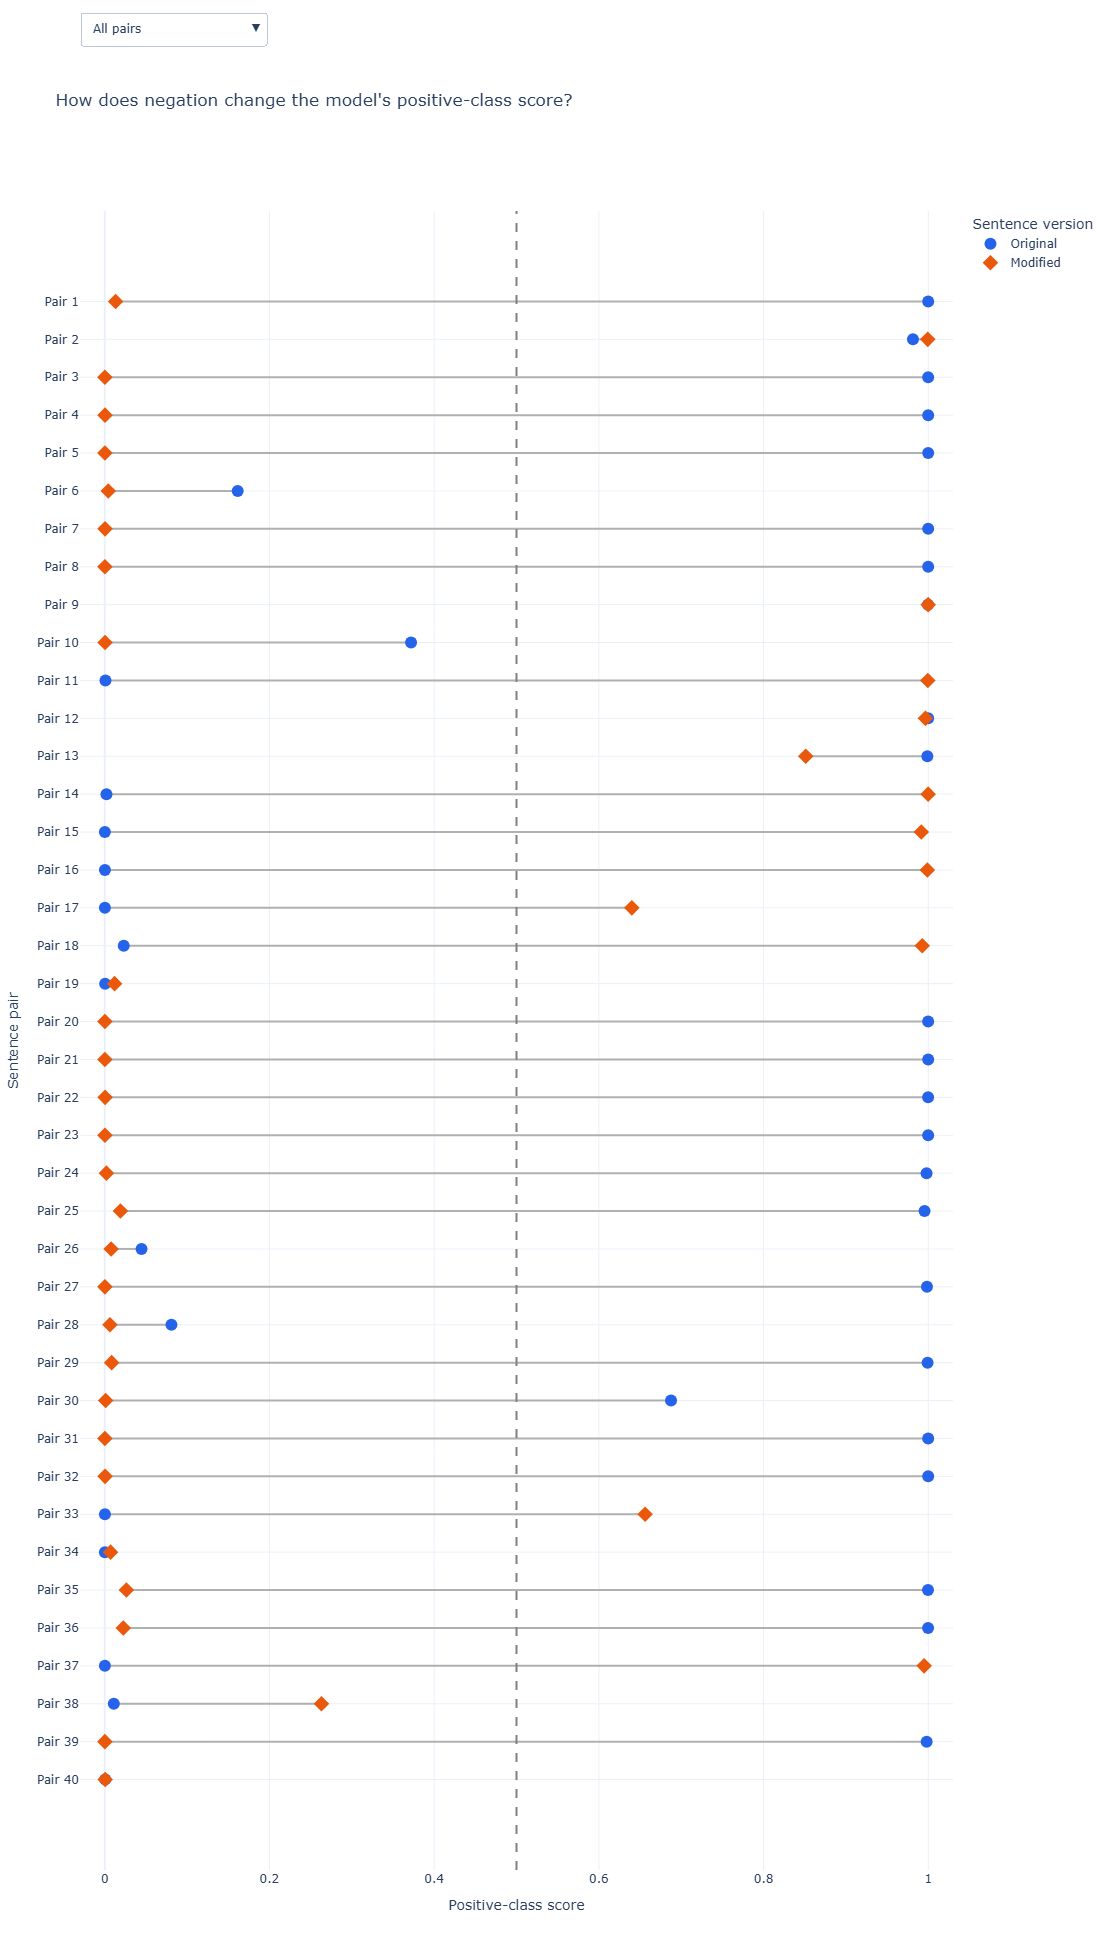

In [28]:
import plotly.graph_objects as go
import textwrap

plot_df = negation_results_df.copy()

fig = go.Figure()

for _, row in plot_df.iterrows():
    fig.add_trace(go.Scatter(
        x=[row["Original Score"], row["Modified Score"]],
        y=[row["Pair ID"], row["Pair ID"]],
        mode="lines",
        line=dict(color="#B0B0B0", width=2),
        showlegend=False,
        hoverinfo="skip"
    ))

for score_column, text_column, name, color, symbol in [
    ("Original Score", "Original", "Original", "#2563EB", "circle"),
    ("Modified Score", "Modified", "Modified", "#EA580C", "diamond")
]:
    hover_data = [
        [
            "<br>".join(textwrap.wrap(text, width=65)),
            movie
        ]
        for text, movie in zip(
            plot_df[text_column], plot_df["Movie"]
        )
    ]

    fig.add_trace(go.Scatter(
        x=plot_df[score_column],
        y=plot_df["Pair ID"],
        mode="markers",
        name=name,
        marker=dict(size=12, color=color, symbol=symbol),
        customdata=hover_data,
        hovertemplate=(
            "<b>%{y}</b> · %{customdata[1]}<br>"
            "%{customdata[0]}<br>"
            "Positive-class score: %{x:.4f}"
            "<extra>" + name + "</extra>"
        )
    ))

fig.add_vline(
    x=0.5,
    line_dash="dash",
    line_color="gray"
)

fig.update_layout(
    title="How does negation change the model's positive-class score?",
    xaxis_title="Positive-class score",
    yaxis_title="Sentence pair",
    template="plotly_white",
    height=max(450, 45 * len(plot_df) + 150),
    hoverlabel=dict(align="left"),
    legend_title_text="Sentence version"
)

fig.update_xaxes(range=[-0.03, 1.03])
fig.update_yaxes(
    categoryorder="array",
    categoryarray=plot_df["Pair ID"].tolist(),
    autorange="reversed"
)

pair_ids = plot_df["Pair ID"].tolist()
changed = plot_df["Orig Label"] != plot_df["Mod Label"]

filter_options = [
    ("All pairs", [True] * len(plot_df)),
    ("Label changed", changed.tolist()),
    ("Label unchanged", (~changed).tolist())
]

for movie in plot_df["Movie"].unique():
    filter_options.append((
        movie,
        (plot_df["Movie"] == movie).tolist()
    ))

buttons = []

for name, mask in filter_options:
    selected_ids = [
        pair_id
        for pair_id, keep in zip(pair_ids, mask)
        if keep
    ]

    buttons.append(dict(
        label=name,
        method="relayout",
        args=[{
            "yaxis.autorange": False,
            "yaxis.range": [-0.5, len(selected_ids) - 0.5],
            "yaxis.categoryorder": "array",
            "yaxis.categoryarray": (
                selected_ids[::-1]
                + [
                    pair_id for pair_id in pair_ids
                    if pair_id not in selected_ids
                ]
            ),
            "height": max(450, 45 * len(selected_ids) + 150)
        }]
    ))

fig.update_layout(
    updatemenus=[dict(
        buttons=buttons,
        direction="down",
        x=0,
        y=1.12,
        xanchor="left",
        yanchor="top"
    )],
    margin=dict(t=130)
)
fig.show()

## Comparing Score Changes

The bar chart orders pairs by their signed score difference.

Bars extending left indicate decreases in the positive-class score.
Bars extending right indicate increases. Longer bars indicate larger
changes in the model output.

Very small changes can match the expected direction while indicating
little sensitivity on this score scale. These cases should be
examined alongside the original and modified texts.

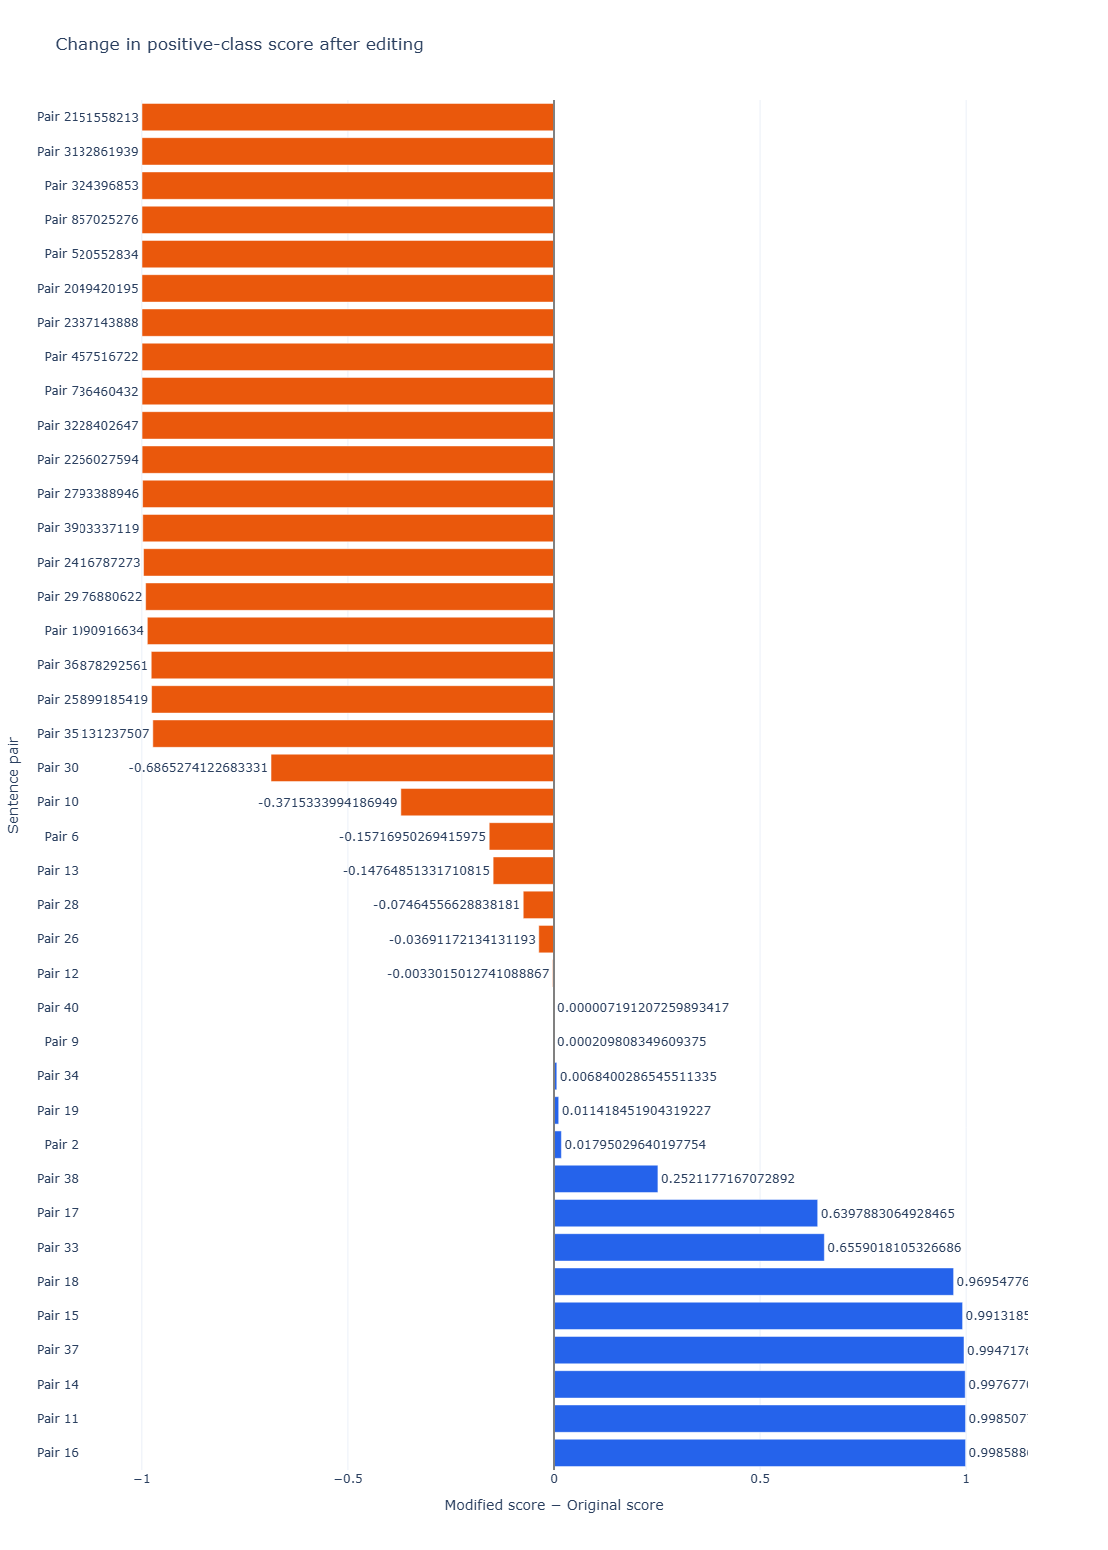

In [29]:
shift_df = negation_results_df.sort_values(
    "Difference (Shift)"
).copy()

shift_colors = [
    "#EA580C" if shift < 0 else "#2563EB"
    for shift in shift_df["Difference (Shift)"]
]

shift_fig = go.Figure(go.Bar(
    x=shift_df["Difference (Shift)"],
    y=shift_df["Pair ID"],
    orientation="h",
    marker_color=shift_colors,
    text=shift_df["Difference (Shift)"],
    texttemplate="%{text:+.3f}",
    textposition="outside",
    customdata=shift_df[
        ["Expected Direction", "Orig Label", "Mod Label"]
    ].values,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Score change: %{x:+.4f}<br>"
        "Expected direction: %{customdata[0]}<br>"
        "Original label: %{customdata[1]}<br>"
        "Modified label: %{customdata[2]}"
        "<extra></extra>"
    )
))

shift_fig.add_vline(x=0, line_color="gray")

shift_fig.update_layout(
    title="Change in positive-class score after editing",
    xaxis_title="Modified score − Original score",
    yaxis_title="Sentence pair",
    template="plotly_white",
    height=max(450, 35 * len(shift_df) + 150),
    showlegend=False
)

shift_fig.update_xaxes(range=[-1.15, 1.15])
shift_fig.update_yaxes(
    categoryorder="array",
    categoryarray=shift_df["Pair ID"].tolist(),
    autorange="reversed"
)

shift_fig.show()

In [30]:
analysis_df = negation_results_df.copy()

analysis_df["Label Changed"] = (
    analysis_df["Orig Label"] != analysis_df["Mod Label"]
)

analysis_df["Direction Matched"] = (
    (
        (analysis_df["Expected Direction"] == "Increase")
        & (analysis_df["Difference (Shift)"] > 0)
    )
    | (
        (analysis_df["Expected Direction"] == "Decrease")
        & (analysis_df["Difference (Shift)"] < 0)
    )
)

print("Total pairs:", len(analysis_df))
print("Label changed:", analysis_df["Label Changed"].sum())
print("Label unchanged:", (~analysis_df["Label Changed"]).sum())
print("Expected direction matched:",
      analysis_df["Direction Matched"].sum())

display(
    analysis_df.groupby("Expected Direction").agg(
        Pairs=("Pair ID", "count"),
        Label_Changes=("Label Changed", "sum"),
        Direction_Matches=("Direction Matched", "sum")
    )
)

display(
    analysis_df[
        ["Pair ID", "Original", "Modified", "Difference (Shift)"]
    ]
    .assign(
        Absolute_Shift=analysis_df["Difference (Shift)"].abs()
    )
    .sort_values("Absolute_Shift")
    .head(5)
    .style.hide(axis="index")
)

Total pairs: 40
Label changed: 28
Label unchanged: 12
Expected direction matched: 40


,Pairs,Label_Changes,Direction_Matches
Expected Direction,,,
Decrease,26,20,26
Increase,14,8,14


Pair ID,Original,Modified,Difference (Shift),Absolute_Shift
Pair 40,"Whalefall can’t commit to a central idea, and clichéd Inuit references only add to its sense of clumsy overreach.","Whalefall can commit to a central idea, and clichéd Inuit references only add to its sense of clumsy overreach.",0.000007,0.000007
Pair 9,"It doesn’t have a memorable ensemble like director Martin McDonagh's best work, [but] Sam Rockwell and John Malkovich are a solid pair.","It does have a memorable ensemble like director Martin McDonagh's best work, [but] Sam Rockwell and John Malkovich are a solid pair.",0.000210,0.000210
Pair 12,"Malkovich is extraordinary, Rockwell is fantastic, and their chemistry is electric.","Malkovich is not extraordinary, Rockwell is fantastic, and their chemistry is electric.",-0.003302,0.003302
Pair 34,"While the storyline had potential, its impact was weakened by the inclusion of certain musical numbers that seemed unnecessary and could have been omitted to allow the narrative to develop more naturally.","While the storyline had potential, its impact was not weakened by the inclusion of certain musical numbers that seemed unnecessary and could have been omitted to allow the narrative to develop more naturally.",0.006840,0.006840
Pair 19,Not interesting then somewhat interesting then interesting then it’s over,Interesting then somewhat interesting then interesting then it’s over,0.011418,0.011418


## Findings

The model achieved 91.06% accuracy on 872 SST-2 validation examples,
with 78 misclassifications.

Across the 40 curated pairs, all score changes followed the manually
assigned expected direction. Predicted labels changed in 28 pairs
and remained unchanged in 12.

The visualizations reveal substantial variation in response size.

- Pair 16 changes from "It was awful." to "It was not awful."
  The positive-class score rises from approximately 0.0003 to 0.999.
  This strong response illustrates why the score should be
  interpreted separately from sentiment intensity.

- Pair 12 negates one positive clause while retaining two others.
  The score decreases slightly and the prediction remains positive.

- Pair 40 removes a negative construction while retaining criticism
  elsewhere in the sentence. The score increases by approximately
  0.000007 and the prediction remains negative. Directional agreement
  therefore includes changes that are extremely small.

- Pair 6 receives a negative prediction even for the original
  favorable recommendation. A change in the expected direction does
  not establish that either prediction is correct.

## Limitations

This is an exploratory study of a small, manually selected set.
The results do not establish general performance on negation.

Expected directions are subjective annotations. The edited texts
do not have independently validated sentiment labels.

Some inputs are excerpts from longer reviews and may lose context.
Some pairs come from the same review and are not independent.

Edits vary in scope. They include single negations, multiple
negations, and changes within mixed opinions. Some edited sentences
are less natural than their originals.

Softmax scores can be highly saturated. A small probability change
does not necessarily imply a small change in the underlying logits.

The experiment describes model responses to input edits. It does
not establish the internal mechanism responsible for those responses.

In [31]:
negation_results_df.to_csv(
    "negation_results.csv",
    index=False,
    encoding="utf-8"
)

fig.write_html(
    "negation_pairs.html",
    include_plotlyjs=True
)

shift_fig.write_html(
    "negation_shifts.html",
    include_plotlyjs=True
)

print("Saved results and interactive charts.")

Saved results and interactive charts.
